# Phase 3 — Analyse exploratoire orientée insights

**Objectif :** comprendre *qui* part et *pourquoi*, pour en tirer des **insights actionnables** : chiffrés, confirmés statistiquement et reliés à une action de rétention.

**Plan**
1. Taux de churn par segment (variables catégorielles)
2. Variables numériques : ancienneté et facturation
3. Tests statistiques et classement des facteurs
4. Segments croisés et revenu à risque
5. Synthèse : les 5 insights clés

> ⚠️ **Corrélation ≠ causalité.** L'EDA met en évidence des *associations*. Par exemple, les clients en contrat mensuel sont aussi plus récents : il faut croiser les variables avant de conclure (section 4).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churn.config import CATEGORICAL_COLS, NUMERIC_COLS, TARGET
from churn.data import load_clean
from churn.eda import churn_rate_table, categorical_association, numeric_association
from churn.viz import (set_style, save_fig, plot_churn_rate, fmt_pct,
                       BLUE, ORANGE, CHURN_COLORS, CHURN_LABELS, TEXT, TEXT_SECONDARY, GRID)

set_style()
df = load_clean()
GLOBAL_RATE = df[TARGET].mean()
print(f"{len(df)} clients — taux de churn global : {fmt_pct(GLOBAL_RATE)}")

7043 clients — taux de churn global : 26,5 %


## 1. Taux de churn par segment

Pour chaque modalité : le taux de churn (barre) comparé à la moyenne globale (ligne pointillée, 26,5 %). `n` = nombre de clients dans le segment.

### 1.1 Contrat et facturation

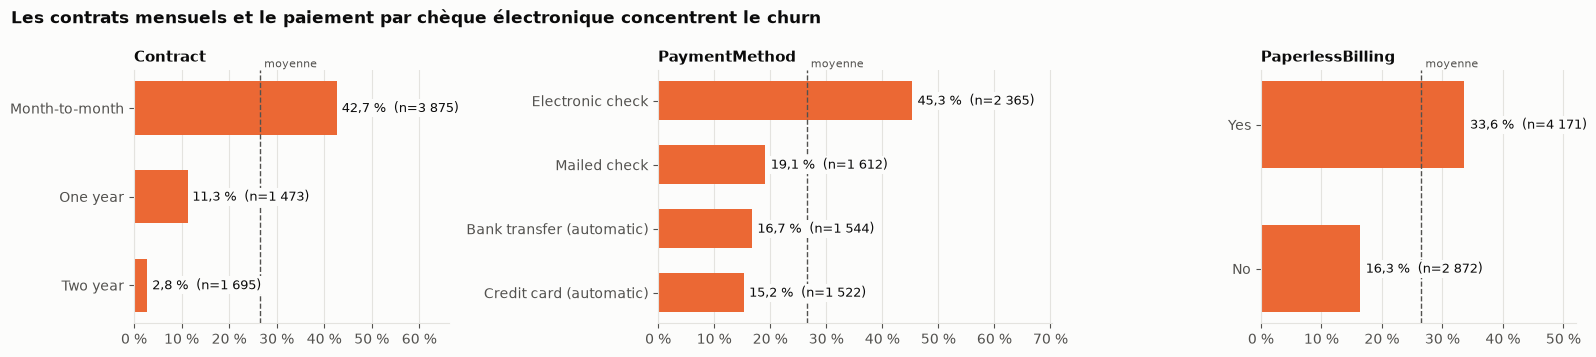

In [2]:
groups = {"Contrat et facturation": ["Contract", "PaymentMethod", "PaperlessBilling"]}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1, 1.25, 1]})
for ax, col in zip(axes, groups["Contrat et facturation"]):
    plot_churn_rate(ax, churn_rate_table(df, col), col, GLOBAL_RATE)
fig.suptitle("Les contrats mensuels et le paiement par chèque électronique concentrent le churn",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "03_churn_contrat_facturation.png")
plt.show()

In [3]:
churn_rate_table(df, "Contract").style.format({"churn_rate": "{:.1%}", "share": "{:.1%}", "lift": "{:.2f}"})

,clients,churners,churn_rate,share,lift
Contract,,,,,
Month-to-month,3875,1655,42.7%,55.0%,1.61
One year,1473,166,11.3%,20.9%,0.42
Two year,1695,48,2.8%,24.1%,0.11


**Lecture :**
- **Contrat** : c'est le facteur le plus spectaculaire. 42,7 % de churn en contrat mensuel contre **2,8 %** en contrat 2 ans, soit **15 fois moins**. Le contrat mensuel concerne 55 % des clients.
- **Paiement** : le **chèque électronique** atteint 45,3 % de churn, contre 15 à 19 % pour les autres moyens. Les deux paiements **automatiques** sont les plus fidèles : le client n'a pas à « décider » de payer chaque mois.
- **Facture dématérialisée** : 33,6 % contre 16,3 %. Probablement un **effet indirect** : ce sont des profils plus connectés, souvent en fibre et en contrat mensuel (à vérifier en section 4).

### 1.2 Services souscrits

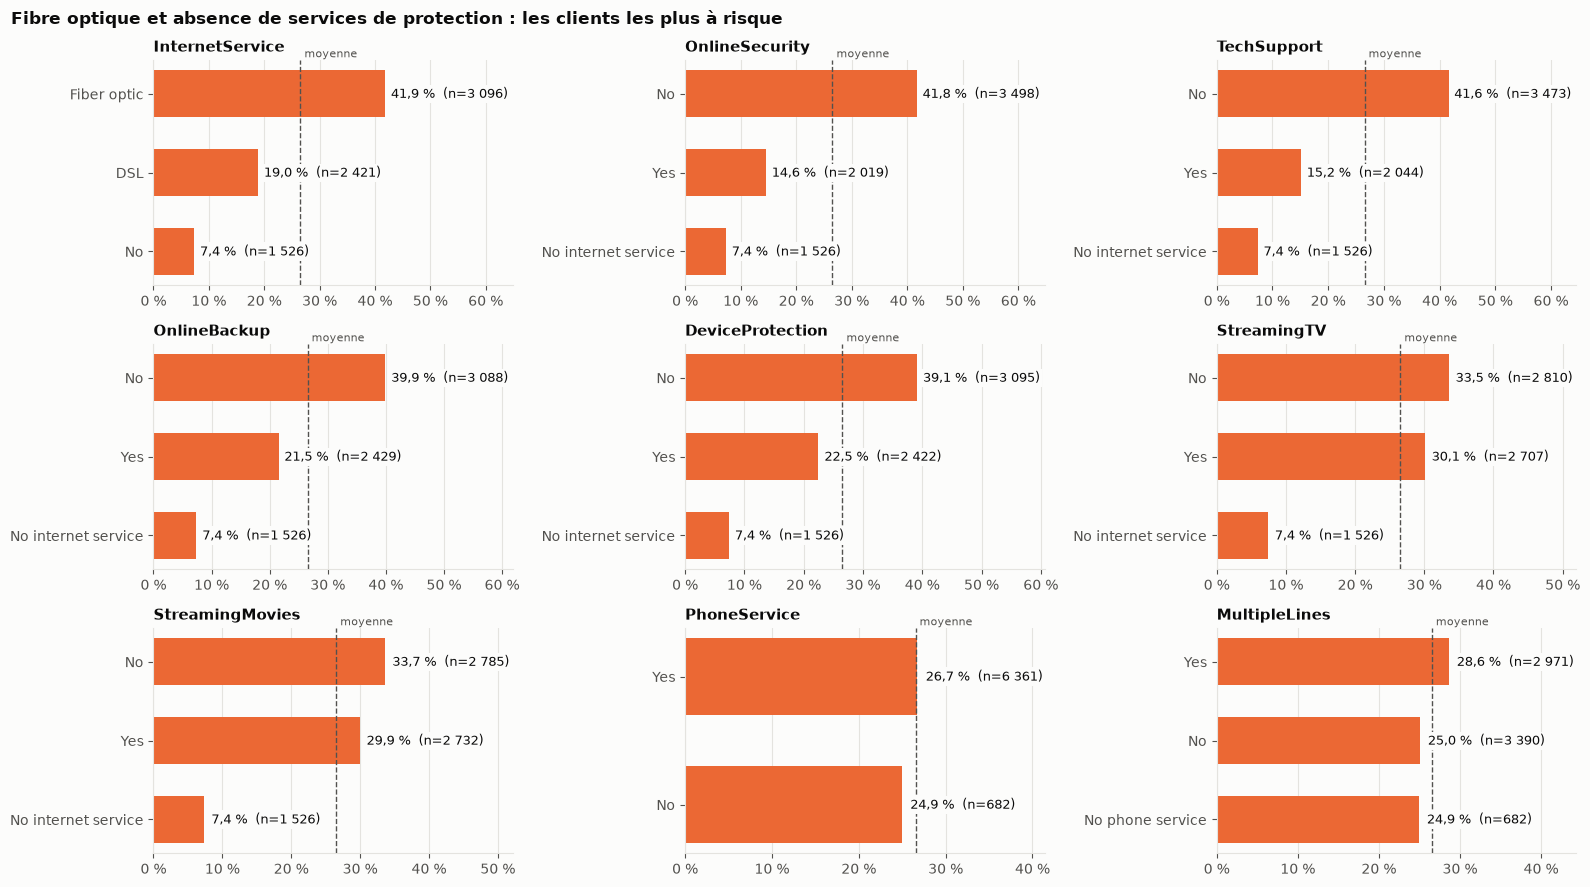

In [4]:
services = ["InternetService", "OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection",
            "StreamingTV", "StreamingMovies", "PhoneService", "MultipleLines"]
fig, axes = plt.subplots(3, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, services):
    plot_churn_rate(ax, churn_rate_table(df, col), col, GLOBAL_RATE)
fig.suptitle("Fibre optique et absence de services de protection : les clients les plus à risque",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "03_churn_services.png")
plt.show()

**Lecture :**
- **Fibre optique : 41,9 % de churn**, contre 19,0 % en DSL. Pourtant la fibre est l'offre « premium ». C'est un signal fort sur le **rapport qualité/prix** ou la **concurrence** sur ce segment.
- **Services de protection et d'assistance** (`OnlineSecurity`, `TechSupport`, `OnlineBackup`, `DeviceProtection`) : les clients **sans** ces services partent environ **2 à 3 fois plus**. Ces services créent de l'attachement et réduisent les frictions.
- **Streaming** : effet faible (33 % contre 30 %). Ce n'est pas un levier de rétention.
- **Téléphone** : aucun effet notable. Le churn se joue sur **l'internet**.
- Les clients **sans internet** sont les plus fidèles (7,4 %) : offre simple, peu chère, peu de raisons de comparer.

### 1.3 Profil client

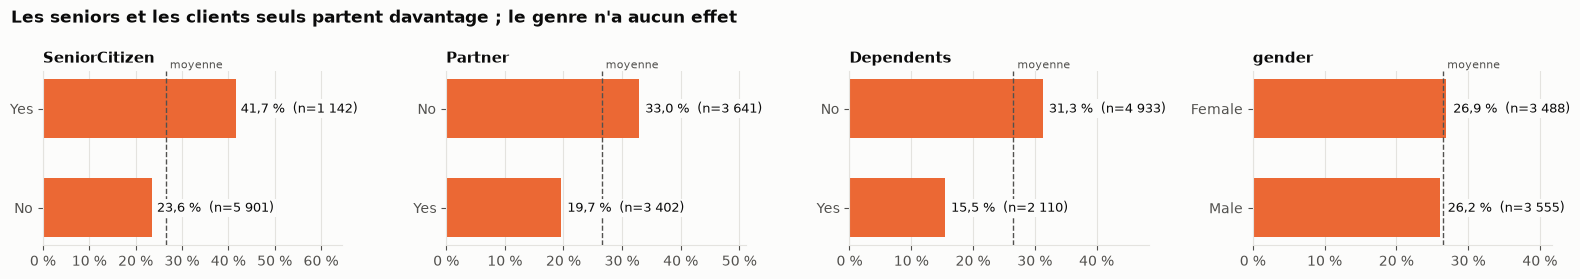

In [5]:
profile = ["SeniorCitizen", "Partner", "Dependents", "gender"]
fig, axes = plt.subplots(1, 4, figsize=(16, 2.8))
for ax, col in zip(axes, profile):
    plot_churn_rate(ax, churn_rate_table(df, col), col, GLOBAL_RATE)
fig.suptitle("Les seniors et les clients seuls partent davantage ; le genre n'a aucun effet",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "03_churn_profil.png")
plt.show()

**Lecture :**
- **Seniors** : 41,7 % contre 23,6 %. Un segment à accompagner (assistance, simplicité de l'offre).
- **Sans partenaire / sans personne à charge** : churn plus élevé. Un foyer « engage » davantage (offres familiales, coût du changement plus élevé).
- **Genre** : 26,9 % contre 26,2 %, **aucune différence**. C'est une bonne nouvelle pour l'éthique du modèle : la variable n'apporte rien et pourra être retirée (Phase 4).